# Tutorial 9: Meshes in ML Pipelines

This tutorial turns meshes into model inputs. You will batch meshes of
different sizes, compute geometric features, and encode boundary conditions.
Then you will build a graph for a message-passing model, train it, and
declare the fields that a model expects with `FieldSchema`. The last section
compares the speed of PhysicsNeMo-Mesh with PyVista.

You will learn:

- How to pad meshes to fixed sizes for batching and `torch.compile`
- How to compute per-point geometric features and store boundary conditions
- How to build graph inputs from mesh adjacency and train a small model on them
- How to declare and check a model's fields with `RankSpec` and `FieldSchema`
- How fast common mesh operations run on a GPU, compared with PyVista and VTK

Prerequisites: [Tutorial 5](tutorial_5_calculus.ipynb) (curvature),
[Tutorial 6](tutorial_6_neighbors_spatial.ipynb) (adjacency), and
[Tutorial 8](tutorial_8_domain_mesh.ipynb) (`DomainMesh`).

Hardware: runs on a CPU, and uses a GPU when one is present. The performance
comparison in Section 8 takes a few minutes.

In [1]:
import json
import platform
import warnings

import numpy as np
import pyvista as pv
import torch
from tensordict import TensorDict

from physicsnemo.mesh import FieldSchema, Mesh, RankSpec
from physicsnemo.mesh.io import to_pyvista
from physicsnemo.mesh.primitives.procedural import lumpy_sphere
from physicsnemo.mesh.primitives.surfaces import cylinder, sphere_icosahedral

pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 400]

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print(f"device: {device}")

device: cuda


## 1. Why mesh processing belongs on the GPU

A training pipeline for physics AI often computes features from each mesh:
normals, curvature, neighbor graphs, or samples of points on the surface.
With a CPU library such as PyVista or VTK, this work runs on the CPU, and the
results move to the GPU at every step. Some PyVista queries also take one
element per call, such as `point_neighbors(i)`.

PhysicsNeMo-Mesh is built on PyTorch tensors. Its operations run on the
device where the mesh lives and act on all elements at once. They are PyTorch
operations, so autograd can differentiate through them. Feature computation
can then happen inside the training loop, on the GPU, instead of in a
separate preprocessing step.

## 2. Batching meshes of different sizes

Meshes in a dataset rarely have the same number of points. To stack them into
one batch, or to reuse a model compiled for fixed shapes, pad them to common
sizes. Use three refinements of the bunny as a small dataset.

In [2]:
bunny = torch.load("assets/bunny.pt", weights_only=False)
dataset = [bunny, bunny.subdivide(1, "loop"), bunny.subdivide(2, "loop")]
for i, m in enumerate(dataset):
    print(f"mesh {i}: {m.n_points:6d} points, {m.n_cells:6d} cells")

mesh 0:    400 points,    792 cells
mesh 1:   1594 points,   3168 cells
mesh 2:   6358 points,  12672 cells


`pad()` pads to the sizes you give. The extra points are copies of the last
point, and the extra cells use only that point, so they have zero area. Padded
entries in floating-point data are NaN. Keep the original sizes to mask the
padding out of a loss.

In [3]:
max_points = max(m.n_points for m in dataset)
max_cells = max(m.n_cells for m in dataset)
padded = [m.pad(target_n_points=max_points, target_n_cells=max_cells) for m in dataset]

points_batch = torch.stack([m.points for m in padded])
valid = torch.stack([torch.arange(max_points) < m.n_points for m in dataset])
print(f"batched points: {tuple(points_batch.shape)}")
print(f"valid points per mesh: {valid.sum(dim=1).tolist()}")

batched points: (3, 6358, 3)
valid points per mesh: [400, 1594, 6358]


Padding every mesh to the largest size wastes memory when sizes vary widely.
`pad_to_next_power(power=1.5)` pads each size up to the next value of
`floor(1.5**n)`. Meshes of similar size then share a shape, so a model
compiled for fixed shapes needs few compiled variants (Section 6).

In [4]:
for m in dataset:
    p = m.pad_to_next_power(power=1.5)
    print(
        f"{m.n_points:6d} -> {p.n_points:6d} points    {m.n_cells:6d} -> {p.n_cells:6d} cells"
    )

   400 ->    437 points       792 ->    985 cells
  1594 ->   2216 points      3168 ->   3325 cells
  6358 ->   7481 points     12672 ->  16834 cells


## 3. Geometric features

Geometric features tell a model about the local shape of the surface. Point
normals give the orientation, and Gaussian and mean curvature describe how the
surface bends. Each is a property of the mesh, computed on the mesh's device.
A `TensorDict` with one row per point keeps them together. The example
surface is a lumpy sphere: closed and manifold, so curvature is defined at
every point.

In [5]:
def extract_features(mesh):
    """Per-point geometric features of a surface mesh."""
    return TensorDict(
        {
            "position": mesh.points,
            "normal": mesh.point_normals,
            "gaussian_curvature": mesh.gaussian_curvature_vertices.unsqueeze(-1),
            "mean_curvature": mesh.mean_curvature_vertices.unsqueeze(-1),
        },
        batch_size=[mesh.n_points],
    )


surface = lumpy_sphere.load(noise_amplitude=0.3, subdivisions=4, seed=0).to(device)
features = extract_features(surface)
print({key: tuple(value.shape) for key, value in features.items()})

{'position': (2562, 3), 'normal': (2562, 3), 'gaussian_curvature': (2562, 1), 'mean_curvature': (2562, 1)}


Check features before you train on them. By default, `mean_curvature_vertices`
is NaN at boundary vertices (pass `include_boundary=True` to the functions in
`physicsnemo.mesh.curvature` to estimate them). The bunny has holes, so some
of its vertices are on the boundary. The count of NaN values below equals the
count of boundary vertices.

In [6]:
refined_bunny = bunny.subdivide(2, "loop")
bunny_curvature = refined_bunny.mean_curvature_vertices
n_boundary = refined_bunny.get_boundary_mesh().cells.unique().numel()
print(
    f"bunny: {bunny_curvature.isnan().sum().item()} NaN values, {n_boundary} boundary vertices"
)
print(
    f"lumpy sphere: {features['mean_curvature'].isnan().sum().item()} NaN values of {surface.n_points}"
)

bunny: 47 NaN values, 47 boundary vertices
lumpy sphere: 0 NaN values of 2562


Inconsistent winding is harder to spot: it gives no NaN values, only wrong
ones, because the sign of curvature follows the normals. Check the
orientation of a mesh before you compute features from it, as in
[Tutorial 7](tutorial_7_quality_repair.ipynb).

Concatenate the features into one matrix for a model that takes a flat input.

In [7]:
feature_matrix = torch.cat(list(features.values()), dim=-1)
print(f"feature matrix: {tuple(feature_matrix.shape)}  (n_points, n_features)")

feature matrix: (2562, 8)  (n_points, n_features)


## 4. Boundary conditions as mesh data

A model for a boundary value problem needs to know which condition applies
where. One way to encode this is a per-cell label plus the prescribed values,
stored in `cell_data`. (The other way is one mesh per boundary patch, in a
`DomainMesh`, as in Tutorial 8.) As an example, label the faces of a closed
cylinder as a pipe: an inlet cap, an outlet cap, and the wall between them.

In [8]:
pipe = cylinder.load(radius=0.5, height=2.0, n_circ=32, n_height=10)
BC_WALL, BC_INLET, BC_OUTLET = 0, 1, 2

is_cap = pipe.cell_normals[:, 2].abs() > 0.9
z = pipe.cell_centroids[:, 2]
bc_type = torch.full((pipe.n_cells,), BC_WALL)
bc_type[is_cap & (z < 0)] = BC_INLET
bc_type[is_cap & (z > 0)] = BC_OUTLET
pipe.cell_data["bc_type"] = bc_type

for name, value in [("wall", BC_WALL), ("inlet", BC_INLET), ("outlet", BC_OUTLET)]:
    print(f"{name:7s} cells: {(bc_type == value).sum().item()}")

wall    cells: 576
inlet   cells: 32
outlet  cells: 32


Draw the labels from above and from below. The wall (0) is dark purple, the
inlet (1) at the bottom is teal, and the outlet (2) at the top is yellow.

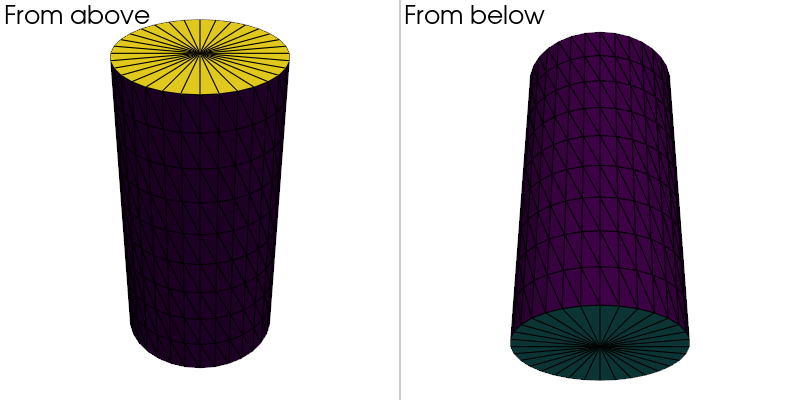

In [9]:
plotter = pv.Plotter(shape=(1, 2))
for column, (title, view) in enumerate(
    [("From above", [1, 1, 1]), ("From below", [1, 1, -1])]
):
    plotter.subplot(0, column)
    pipe.draw(
        cell_scalars="bc_type",
        cmap="viridis",
        alpha_points=0.0,
        ax=plotter,
        show=False,
        backend_options={"n_colors": 3, "show_scalar_bar": False},
    )
    plotter.add_text(title, font_size=12)
    plotter.view_vector(view)
plotter.show()

Store the prescribed values in a nested `TensorDict`: a velocity at the
inlet and a pressure at the outlet. NaN marks "not prescribed", so a loss can
skip those entries.

In [10]:
bc_values = TensorDict(
    {
        "velocity": torch.full((pipe.n_cells, 3), float("nan")),
        "pressure": torch.full((pipe.n_cells,), float("nan")),
    },
    batch_size=[pipe.n_cells],
)
bc_values["velocity"][bc_type == BC_INLET] = torch.tensor([0.0, 0.0, 1.0])
bc_values["velocity"][bc_type == BC_WALL] = 0.0  # no-slip
bc_values["pressure"][bc_type == BC_OUTLET] = 0.0
pipe.cell_data["bc_values"] = bc_values
print(pipe)

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=322, n_cells=640)
    cell_data: {
        bc_type  : (),
        bc_values: {pressure: (), velocity: (3,)}}


A model usually takes the label as a one-hot vector.

In [11]:
bc_one_hot = torch.nn.functional.one_hot(bc_type, num_classes=3).float()
print(f"one-hot labels: {tuple(bc_one_hot.shape)}")

one-hot labels: (640, 3)


## 5. End-to-end: from a mesh to a trained graph model

A graph neural network treats mesh points as nodes and mesh edges as graph
edges. The point-to-points adjacency gives the edges directly. Its
`expand_to_pairs()` method returns one `(source, target)` pair per edge, in
each direction.

In [12]:
def mesh_to_graph(mesh):
    """Node features, edge index, and edge features of a surface mesh."""
    node_features = torch.cat([mesh.points, mesh.point_normals], dim=-1)
    source, target = mesh.get_point_to_points_adjacency().expand_to_pairs()
    edge_vectors = mesh.points[target] - mesh.points[source]
    edge_features = torch.cat(
        [edge_vectors, edge_vectors.norm(dim=-1, keepdim=True)], dim=-1
    )
    return node_features, torch.stack([source, target]), edge_features


nodes, edge_index, edges = mesh_to_graph(surface)
print(
    f"nodes: {tuple(nodes.shape)}, edge_index: {tuple(edge_index.shape)}, edges: {tuple(edges.shape)}"
)

nodes: (2562, 6), edge_index: (2, 15360), edges: (15360, 4)


Now train a one-layer message-passing model to predict the mean curvature of
each point from positions and normals. Each node sums messages from its
neighbors, and an MLP maps its own features plus the summed messages to the
output. Curvature depends on how normals change between neighbors, so the
edges carry the information the model needs.

In [13]:
class MessagePassing(torch.nn.Module):
    def __init__(self, n_node, n_edge, n_hidden=64):
        super().__init__()
        self.message = torch.nn.Sequential(
            torch.nn.Linear(2 * n_node + n_edge, n_hidden),
            torch.nn.SiLU(),
            torch.nn.Linear(n_hidden, n_hidden),
        )
        self.update = torch.nn.Sequential(
            torch.nn.Linear(n_node + n_hidden, n_hidden),
            torch.nn.SiLU(),
            torch.nn.Linear(n_hidden, 1),
        )

    def forward(self, nodes, edge_index, edges):
        source, target = edge_index
        messages = self.message(
            torch.cat([nodes[source], nodes[target], edges], dim=-1)
        )
        summed = torch.zeros(nodes.shape[0], messages.shape[1], device=nodes.device)
        summed.index_add_(0, source, messages)
        return self.update(torch.cat([nodes, summed], dim=-1)).squeeze(-1)

Standardize the target to zero mean and unit variance, and scale the edge
features so that the mean edge length is 1. Then the default learning rate
works.

In [14]:
curvature = surface.mean_curvature_vertices
target = (curvature - curvature.mean()) / curvature.std()
edges_scaled = edges / edges[:, -1:].mean()

model = MessagePassing(nodes.shape[1], edges.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for step in range(301):
    prediction = model(nodes, edge_index, edges_scaled)
    loss = torch.nn.functional.mse_loss(prediction, target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.4f}")

step   0  loss 1.0035
step  50  loss 0.1576
step 100  loss 0.0809


step 150  loss 0.0536
step 200  loss 0.0375
step 250  loss 0.0235


step 300  loss 0.0163


The printed loss is the training loss on this one mesh. It falls well below
1, the loss of always predicting the mean. Every step ran on the same device
as the mesh, with no conversion to NumPy or VTK. In a real pipeline, the
target is a simulated field. You compute the mesh features per sample inside
the data loader or the training step.

## 6. Compiling mesh code with torch.compile

`torch.compile` traces a function into fused kernels. Most PhysicsNeMo-Mesh
operations can be traced. A function that builds a `Mesh` from raw tensors
and computes features from it can then be compiled as a whole.
`fullgraph=True` makes this a requirement: compilation fails if any part of
the function cannot be traced.

In [15]:
def cell_features(points, cells):
    mesh = Mesh(points=points, cells=cells)
    return torch.cat([mesh.cell_normals, mesh.cell_areas.unsqueeze(-1)], dim=-1)


compiled_cell_features = torch.compile(cell_features, fullgraph=True)
compiled = compiled_cell_features(surface.points, surface.cells)
eager = cell_features(surface.points, surface.cells)
print(
    f"output: {tuple(compiled.shape)}, matches eager: {torch.allclose(compiled, eager, atol=1e-6)}"
)

output: (5120, 4), matches eager: True


A compiled function is specialized to the shapes it saw. When a new shape
arrives, PyTorch recompiles it, and by default it switches to a graph with
dynamic shapes when the second shape arrives. With
`torch.compile(dynamic=False)`, every new shape compiles a new variant, and
after `torch._dynamo.config.recompile_limit` variants (8 by default) the
function falls back to eager mode. Pad inputs with `pad_to_next_power()`
(Section 2) to keep the number of variants small.

## 7. Declaring a model's fields with FieldSchema

A model that consumes mesh data expects named fields: a `pressure` scalar,
a `velocity` vector, maybe a `stress` tensor. Two things must be clear for
each field. First, its *rank*, the number of spatial indices: 0 for a scalar,
1 for a vector, 2 for a matrix-like tensor. The rank decides how the field
changes when the frame rotates. Second, whether the data actually contains it,
with that rank. `physicsnemo.mesh.fields` provides two types for this:

- `RankSpec` describes one field: its `rank`, whether a tensor of rank 2 or
  more is `symmetric`, and its `parity`.
- `FieldSchema` maps field names to `RankSpec` values, and checks data against
  them.

### RankSpec: how one field transforms

Under a rotation `R`, a scalar does not change, a vector `v` becomes `R v`, and
a rank-2 tensor `T` becomes `R T Rᵀ`. Parity matters under reflections. A
true vector such as velocity reflects like a position. A *pseudovector* such
as vorticity in 3D picks up an extra factor of -1 under a reflection: it
transforms as `det(R) R v`. Declare it with `parity="odd"`.

`shape()` gives the trailing shape of a field in a given spatial dimension,
and `numel()` the number of stored components. A symmetric rank-2 tensor in
3D stores 9 components, of which 6 are independent.

In [16]:
specs = {
    "pressure": RankSpec(0),
    "velocity": RankSpec(1),
    "stress": RankSpec(2, symmetric=True),
    "vorticity": RankSpec(1, parity="odd"),
}
for name, spec in specs.items():
    print(
        f"{name:10s} {spec!r:40s} shape in 3D: {spec.shape(3)}, stored components: {spec.numel(3)}"
    )

pressure   RankSpec(rank=0)                         shape in 3D: (), stored components: 1
velocity   RankSpec(rank=1)                         shape in 3D: (3,), stored components: 3
stress     RankSpec(rank=2, symmetric=True)         shape in 3D: (3, 3), stored components: 9
vorticity  RankSpec(rank=1, parity='odd')           shape in 3D: (3,), stored components: 3


A `RankSpec` is a read-only `dict` that holds only the attributes that differ
from their defaults, so it prints and serializes as you write it.

In [17]:
print(dict(RankSpec(2, symmetric=True)))
print(RankSpec(1) == RankSpec(1, symmetric=False, parity="even"))

{'rank': 2, 'symmetric': True}
True


### FieldSchema: the fields of a model

`FieldSchema.parse()` reads a declaration. A field is a `RankSpec` or a mapping
such as `{"rank": 0}`. A group of fields is a nested mapping, or the same
nesting written with dots in the name. Both forms give the same dotted names.

In [18]:
schema = FieldSchema.parse(
    {
        "pressure": {"rank": 0},
        "velocity": RankSpec(1),
        "wall": {"shear": {"rank": 1}},  # a nested group ...
        "wall.heat_flux": {"rank": 0},  # ... or the same nesting, dotted
    }
)
print(list(schema))

['pressure', 'velocity', 'wall.shear', 'wall.heat_flux']


`ranks` gives the rank of each field, and `count(rank)` the number of fields
of a rank. A model can size its layers from these, for example one input
channel per scalar and one vector channel per vector.

In [19]:
print(schema.ranks)
print(f"scalars: {schema.count(0)}, vectors: {schema.count(1)}")

{'pressure': 0, 'velocity': 1, 'wall.shear': 1, 'wall.heat_flux': 0}
scalars: 2, vectors: 2


A schema is also a read-only `dict`, so it serializes to JSON as written, and
`parse()` reads the JSON back. Models in PhysicsNeMo save their constructor
arguments as JSON in checkpoints, so a schema can be one of them.

In [20]:
text = json.dumps(schema)
print(text)
print(FieldSchema.parse(json.loads(text)) == schema)

{"pressure": {"rank": 0}, "velocity": {"rank": 1}, "wall.shear": {"rank": 1}, "wall.heat_flux": {"rank": 0}}
True


Invalid declarations fail when you parse them, not later in training. For
example, a bare integer is refused, because it does not say which attribute
it sets.

In [21]:
try:
    FieldSchema.parse({"pressure": 0})
except TypeError as error:
    print(f"TypeError: {error}")

TypeError: fields['pressure'] must be a RankSpec or a mapping with a 'rank' key; got int (write {'rank': 0})


### Check data against a schema

Mesh data lives in `TensorDict` objects: `point_data`, `cell_data`, and
`global_data`. Nested groups are nested `TensorDict` objects, so the schema
name `"wall.shear"` is the key `("wall", "shear")`. `FieldSchema.key()`
converts a name to a key.

In [22]:
sample = sphere_icosahedral.load(subdivisions=2)
n = sample.n_points
sample.point_data["pressure"] = sample.points[:, 2]
sample.point_data["velocity"] = torch.randn(n, 3)
sample.point_data["wall"] = TensorDict(
    {"shear": torch.randn(n, 3), "heat_flux": torch.randn(n)}, batch_size=[n]
)
sample.point_data["mesh_id"] = torch.zeros(n)  # not declared in the schema

print(FieldSchema.key("wall.shear"))
print(sample.point_data[FieldSchema.key("wall.shear")].shape)

('wall', 'shear')
torch.Size([162, 3])


`check(data, label=...)` raises a `ValueError` unless the data holds every
declared field at its declared rank. A field's rank in the data is its
number of dimensions after the batch dimension. Shape `(n,)` is rank 0, and
`(n, 3)` is rank 1. `check()` compares only the number of dimensions, not
their sizes, so a 2D velocity of shape `(n, 2)` also passes. Extra fields,
such as `mesh_id`, are allowed.

In [23]:
schema.check(sample.point_data, label="point_data")
print("point_data matches the schema")

point_data matches the schema


If a field is missing or has the wrong rank, the error lists every problem at
once.

In [24]:
broken = sample.point_data.exclude("pressure")
broken["velocity"] = broken["velocity"].norm(dim=-1)  # a speed, not a vector
try:
    schema.check(broken, label="point_data")
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: point_data does not contain its declared fields:
  - missing field 'pressure' (declared rank 0)
  - rank mismatch for 'velocity': declared 1, got 0


Select the declared fields, in schema order, with `FieldSchema.key()`. This
drops undeclared fields before they reach the model.

In [25]:
inputs = sample.point_data.select(*(FieldSchema.key(name) for name in schema))
print(list(inputs.keys(include_nested=True, leaves_only=True)))

['pressure', 'velocity', ('wall', 'shear'), ('wall', 'heat_flux')]


`FieldSchema.from_tensordict()` builds a schema from the shapes of existing
data. Shapes give ranks only, so symmetry and parity take their defaults.

In [26]:
print(FieldSchema.from_tensordict(inputs).ranks)

{'pressure': 0, 'velocity': 1, 'wall.shear': 1, 'wall.heat_flux': 0}


### How GLOBE uses FieldSchema

GLOBE (`physicsnemo.experimental.models.globe`) is a model that predicts
fields from boundary data. It takes three kinds of schema:

- `output_schema`: the fields it predicts
- `boundary_source_schemas`: one schema per boundary condition type, for the
  `cell_data` of each boundary mesh
- `global_schema`: domain-level inputs, such as a Reynolds number

Its constructor parses each schema, and sizes its networks with `count(0)`
and `count(1)`. In its forward pass, it checks each boundary mesh's
`cell_data` and the `global_data` with `check()`. It selects the declared
`global_data` fields with `key()`, and the declared boundary fields with
`cell_data.flatten_keys().select(...)`, which also uses dotted names. GLOBE
builds its features from scalars and true vectors only, so it refuses other
declarations when you construct it.

Importing from `physicsnemo.experimental` warns that the API there can
change. The cell below silences that warning.

In [27]:
from physicsnemo.core.warnings import ExperimentalFeatureWarning  # noqa: E402

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ExperimentalFeatureWarning)
    from physicsnemo.experimental.models.globe import GLOBE

model_kwargs = dict(
    n_spatial_dims=3,
    boundary_source_schemas={"no_slip": {}},
    reference_length_names=["length"],
    reference_area=1.0,
)
globe = GLOBE(
    output_schema={"pressure": {"rank": 0}, "wall_shear": {"rank": 1}}, **model_kwargs
)
print(globe.output_schema)

try:
    GLOBE(output_schema={"stress": {"rank": 2, "symmetric": True}}, **model_kwargs)
except NotImplementedError as error:
    print(f"NotImplementedError: {error}")

FieldSchema({'pressure': RankSpec(rank=0), 'wall_shear': RankSpec(rank=1)})
NotImplementedError: output_schema['stress']: rank-2 fields are not supported; GLOBE implements scalars (rank 0) and vectors (rank 1)


## 8. Performance compared with PyVista

How much faster is a GPU for these operations? The `benchmarks` package next
to this notebook times the same operations in PyVista and in
PhysicsNeMo-Mesh. PyVista calls VTK on the CPU, and PhysicsNeMo-Mesh runs on
the CPU and on the GPU. `benchmark()` reports the fastest of several runs,
after warm-up runs.

The outputs stored in this notebook come from one NVIDIA GB300 GPU and the
Arm Neoverse V2 cores of an NVIDIA Grace CPU. Your numbers depend on your
hardware. The CPU comparison also depends on thread counts. PyTorch uses the
number of threads printed below. VTK runs its threaded filters through
`vtkSMPTools`, whose backend and thread count are also printed below. Many
VTK filters run on one thread whatever the backend.

In [28]:
from vtkmodules.vtkCommonCore import vtkSMPTools  # noqa: E402

from benchmarks import benchmark, plot_speedup_chart, raw_ops  # noqa: E402

print(
    f"PyTorch {torch.__version__}, PyVista {pv.__version__}, CPU: {platform.machine()}, {torch.get_num_threads()} threads"
)
print(
    f"VTK SMP backend: {vtkSMPTools.GetBackend()}, {vtkSMPTools.GetEstimatedNumberOfThreads()} threads"
)
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch 2.13.0+cu130, PyVista 0.49.0, CPU: aarch64, 144 threads
VTK SMP backend: Sequential, 1 threads
GPU: NVIDIA GB300


The test mesh is the bunny after four levels of Loop subdivision, about
200,000 triangles. Each row pairs a PyVista call with the matching function
in `benchmarks/raw_ops.py`, run without `torch.compile`.

PyVista has no batched neighbor query: `point_neighbors(i)` and
`cell_neighbors(i)` take one element per call. For point neighbors, the
PyVista row instead extracts all edges with `extract_all_edges()` and builds
the neighbor lists with NumPy (`pyvista_point_neighbors` below). For cell
neighbors, the PyVista row times a Python loop over `cell_neighbors(i)`.

In [29]:
mesh = bunny.subdivide(4, "loop")
pv_mesh = to_pyvista(mesh)
pv_mesh.point_data["z"] = mesh.points[:, 2].numpy()
print(mesh)


def pyvista_point_neighbors(m):
    """All point neighbors from PyVista's edges, as (offsets, indices) arrays."""
    lines = m.extract_all_edges().lines.reshape(-1, 3)[:, 1:]
    source = np.concatenate([lines[:, 0], lines[:, 1]])
    target = np.concatenate([lines[:, 1], lines[:, 0]])
    counts = np.bincount(source, minlength=m.n_points)
    offsets = np.concatenate([[0], np.cumsum(counts)])
    return offsets, target[np.argsort(source, kind="stable")]


pyvista_ops = {
    "normals": lambda: pv_mesh.compute_normals(
        cell_normals=True, point_normals=False, consistent_normals=False
    ),
    "curvature": lambda: pv_mesh.curvature(curv_type="gaussian"),
    "gradient": lambda: pv_mesh.compute_derivative(scalars="z"),
    "subdivision": lambda: pv_mesh.subdivide(nsub=1, subfilter="loop"),
    "neighbors_p2p": lambda: pyvista_point_neighbors(pv_mesh),
    "neighbors_c2c": lambda: [
        pv_mesh.cell_neighbors(i, "edges") for i in range(pv_mesh.n_cells)
    ],
    "smoothing": lambda: pv_mesh.smooth(n_iter=50, relaxation_factor=0.1),
    "transforms": lambda: (
        pv_mesh.translate((1.0, 2.0, 3.0), inplace=False)
        .rotate_x(45, inplace=False)
        .rotate_y(30, inplace=False)
        .scale(2.0, inplace=False)
    ),
}


def mesh_ops(m):
    """The PhysicsNeMo-Mesh counterparts: (function name in raw_ops, arguments)."""
    p, c = m.points, m.cells
    angle_x, angle_y = torch.tensor(torch.pi / 4), torch.tensor(torch.pi / 6)
    return {
        "normals": ("cell_normals", (p, c)),
        "curvature": ("gaussian_curvature", (p, c)),
        "gradient": ("gradient", (p, c, p[:, 2].clone())),
        "subdivision": ("subdivide", (p, c)),
        "neighbors_p2p": ("p2p_neighbors", (p, c)),
        "neighbors_c2c": ("c2c_neighbors", (p, c)),
        "smoothing": ("smooth", (p, c, 50, 0.1)),
        "transforms": (
            "transforms",
            (
                p,
                c,
                torch.tensor([1.0, 2.0, 3.0], device=p.device),
                angle_x,
                angle_y,
                2.0,
            ),
        ),
    }

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=101470, n_cells=202752)


Run every variant. This cell takes a few minutes. Most of the time goes to
the PyVista cell-neighbor loop.

In [30]:
variants = {"pnm_cpu_raw": "cpu"}
if torch.cuda.is_available():
    variants["pnm_gpu_raw"] = "cuda"

results = {name: {"sizes": [mesh.n_cells]} for name in pyvista_ops}
for name, op in pyvista_ops.items():
    results[name]["pyvista"] = [
        benchmark(f"{name:14s} PyVista", op, warmup=1, verbose=False)[0]
    ]
for variant, variant_device in variants.items():
    for name, (function, args) in mesh_ops(mesh.to(variant_device)).items():
        seconds, _ = benchmark(
            name, lambda: getattr(raw_ops, function)(*args), verbose=False
        )
        results[name][variant] = [seconds]

The table lists the fastest time of each variant in milliseconds.

In [31]:
columns = ["pyvista", *variants]
print(f"{'operation':15s}" + "".join(f"{c:>18s}" for c in columns))
for name, row in results.items():
    print(f"{name:15s}" + "".join(f"{1000 * row[c][0]:18.2f}" for c in columns))

operation                 pyvista       pnm_cpu_raw       pnm_gpu_raw
normals                      5.18              3.11              0.45
curvature                   16.61             29.64              3.05
gradient                    80.84             85.49             26.91
subdivision                237.40             68.64              5.31
neighbors_p2p               45.18             15.41              1.03
neighbors_c2c            15068.58             31.19              1.90
smoothing                  160.75            255.98             17.64
transforms                   4.85              2.53              2.62


For comparison, the per-point loop over `point_neighbors(i)` takes much
longer than the edge-based construction.

In [32]:
loop_seconds, _ = benchmark(
    "point_neighbors loop",
    lambda: [pv_mesh.point_neighbors(i) for i in range(pv_mesh.n_points)],
    warmup=0,
    verbose=False,
)
print(f"point_neighbors(i) loop: {1000 * loop_seconds:.0f} ms")
print(
    f"extract_all_edges + NumPy: {1000 * results['neighbors_p2p']['pyvista'][0]:.0f} ms"
)

point_neighbors(i) loop: 11605 ms
extract_all_edges + NumPy: 45 ms


The chart shows the same results as speedups over PyVista, on a log scale.

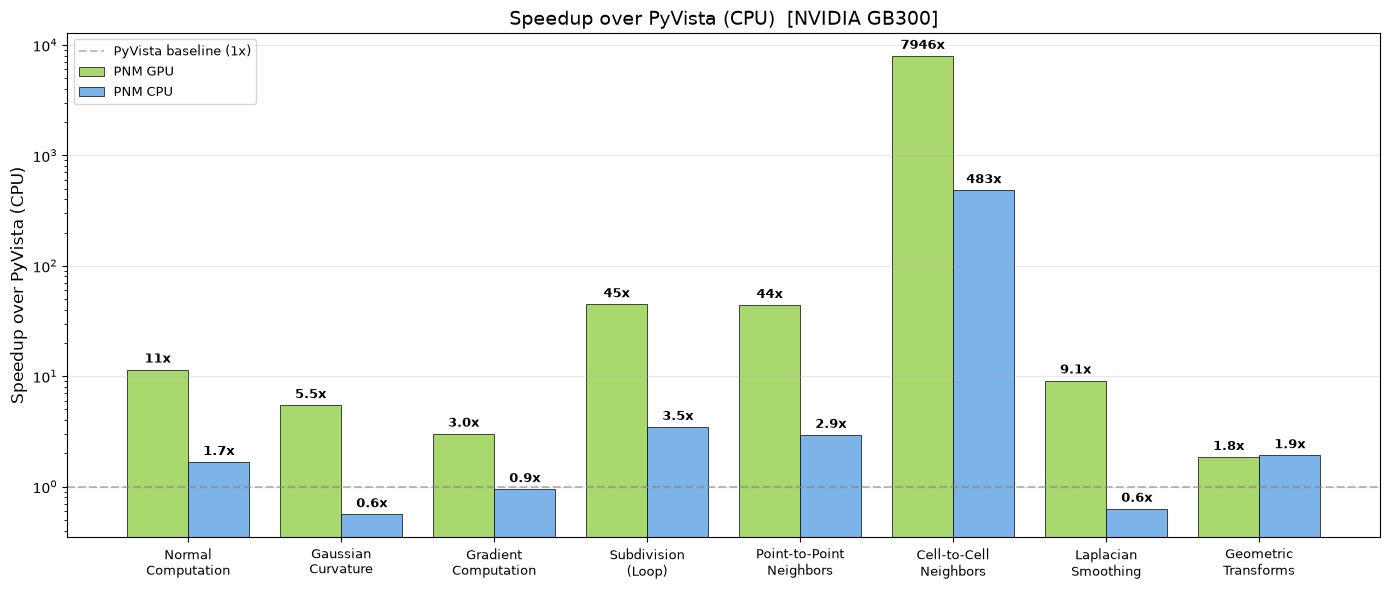

In [33]:
plot_speedup_chart(
    results,
    title_suffix=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    save_path=None,
)

Cell neighbors gain the most. The PyVista row answers them one element at a
time, while PhysicsNeMo-Mesh computes all of them in one vectorized pass. The
point-neighbor row shows how much of that gap a batched NumPy construction
closes. On the GPU, the other operations are also faster than PyVista at
this mesh size. On the CPU, PhysicsNeMo-Mesh is faster than VTK for some
operations and slower for others, such as curvature and smoothing. In the
stored run, VTK used its Sequential backend (one thread), and PyTorch used 144
threads. CPU timings also vary from run to run on a shared machine. On small meshes, the
fixed cost of launching GPU kernels can outweigh the gain.

## Summary

- `pad()` and `pad_to_next_power()` give meshes common sizes for batching and
  for compiled models. Padding cells have zero area, and padding data is NaN.
- Normals, curvature, and adjacency are mesh properties computed on the mesh's
  device. A `TensorDict` keeps per-point features together.
- Boundary conditions can live in `cell_data` as labels and nested
  `TensorDict` values, or as separate boundary meshes in a `DomainMesh`.
- `get_point_to_points_adjacency().expand_to_pairs()` gives a graph's edge
  index, and the whole pipeline, including training, stays on one device.
- Most mesh code compiles with `torch.compile`.
- `RankSpec` declares how one field transforms. `FieldSchema` declares a
  model's fields, serializes to JSON, and checks data with `check()`.
- On a GPU, PhysicsNeMo-Mesh runs common operations faster than PyVista. Cell
  neighbors, which PyVista finds one cell per call, gain the most.

## Next steps

This is the last tutorial in the series. To go further:

- API reference:
  [fields](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/fields.html),
  [neighbors](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/neighbors.html),
  [core (`Mesh`)](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/core.html).
- User Guide:
  [Mesh in ML Pipelines](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/ml_integration.html)
  and [Fields, Ranks, and Schemas](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/fields.html).
- The [PhysicsNeMo-Mesh overview](../../../physicsnemo/mesh/README.md) lists every
  submodule.